# Heart Disease Prediction & Multi-Model Evaluation

- **Author:** Shivshankar Dhareppa Mali
- **Domain:** Supervised Binary Classification
- **Dataset:** Heart Disease Dataset (UCI Cleveland / Kaggle)
- **Objective:** Benchmark 3 classification models (Logistic Regression, Random Forest, KNN) to identify coronary disease from clinical metrics.


### 1. Core library imports

In [1]:
import os
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')


### 2. Scikit-learn algorithms and evaluation metrics

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, confusion_matrix, classification_report
)


### 3. Plot configuration

In [3]:
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams.update({
    'figure.dpi': 120,
    'figure.autolayout': True,
    'font.size': 10.5,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10.5,
    'axes.labelweight': 'bold'
})


### 4. Locate dataset path

In [4]:
import urllib.request
from pathlib import Path

data_path = Path("data/heart.csv") if Path("data/heart.csv").exists() else Path("project-02-heart-disease-ml/data/heart.csv")

# Auto-download dataset if running in Google Colab
if not data_path.exists():
    Path("data").mkdir(parents=True, exist_ok=True)
    data_path = Path("data/heart.csv")
    url = "https://raw.githubusercontent.com/shiv123-coder/CardioML/main/data/heart.csv"
    urllib.request.urlretrieve(url, data_path)

print("Dataset ready:", data_path.resolve())


Dataset ready: /content/data/heart.csv


### 5. Load raw dataset

In [5]:
df_raw = pd.read_csv(data_path)
print(f"Loaded raw dataset: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()


Loaded raw dataset: 1025 rows, 14 columns


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


### 6. Column data types and missing values

In [6]:
df_raw.info()
print("\nMissing values count:")
print(df_raw.isna().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing values count:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target     

### 7. Duplicate row audit

In [7]:
raw_dups = df_raw.duplicated().sum()
print(f"Duplicate rows in raw dataset: {raw_dups} (out of {len(df_raw)} records)")


Duplicate rows in raw dataset: 723 (out of 1025 records)


### Step 1: Preprocessing decisions and justifications
1. **Deduplication**: The Kaggle release contains 1,025 rows sampled from the original 303-patient UCI Cleveland study. Exactly 723 records are duplicate rows. If split after duplication, identical patients leak into both train and test splits, producing an artificial accuracy above 98%. Deduplicating to **302 unique patients** ensures realistic out-of-sample evaluation.
2. **Stratified train/test split**: An 80/20 train/test partition (241 train, 61 test) preserves the positive-to-negative outcome ratio across splits.
3. **Column transformations**:
   - Continuous variables (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`, `ca`) are standardized via `StandardScaler` to have zero mean and unit variance.
   - Categorical variables (`cp`, `restecg`, `slope`, `thal`) are one-hot encoded with `drop='first'` to prevent multicollinearity in linear models.
   - Binary variables (`sex`, `exang`) pass through directly as 0/1 indicator flags.
4. **Pipeline architecture**: Transformers are wrapped inside scikit-learn `Pipeline` objects to prevent data leakage during cross-validation and testing.


### 8. Deduplicate dataset to unique patient records

In [8]:
df = df_raw.drop_duplicates().copy().reset_index(drop=True)
print("Unique patient cohort size:", df.shape[0])
print("\nTarget class distribution:")
print(df['target'].value_counts())


Unique patient cohort size: 302

Target class distribution:
target
1    164
0    138
Name: count, dtype: int64


### 9. Statistical summary of patient cohort

In [9]:
df.describe().round(2)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00
mean,54.42,0.68,0.96,131.60,246.50,0.15,0.53,149.57,0.33,1.04,1.40,0.72,2.31,0.54
std,9.05,0.47,1.03,17.56,51.75,0.36,0.53,22.90,0.47,1.16,0.62,1.01,0.61,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,48.00,0.00,0.00,120.00,211.00,0.00,0.00,133.25,0.00,0.00,1.00,0.00,2.00,0.00
50%,55.50,1.00,1.00,130.00,240.50,0.00,1.00,152.50,0.00,0.80,1.00,0.00,2.00,1.00
75%,61.00,1.00,2.00,140.00,274.75,0.00,1.00,166.00,1.00,1.60,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,4.00,3.00,1.00


## Step 2: Feature engineering and selection

Analyzing feature correlations with the target and assessing clinical relevance.


### 10. Feature correlations with disease status

In [10]:
corr = df.corr()
target_corr = corr['target'].drop('target').sort_values()
pd.DataFrame({'Pearson Correlation with Target': target_corr.round(3)})


,Pearson Correlation with Target
exang,-0.436
oldpeak,-0.429
ca,-0.409
thal,-0.343
sex,-0.284
age,-0.221
trestbps,-0.146
chol,-0.081
fbs,-0.027
restecg,0.135


### 11. Correlation matrix heatmap

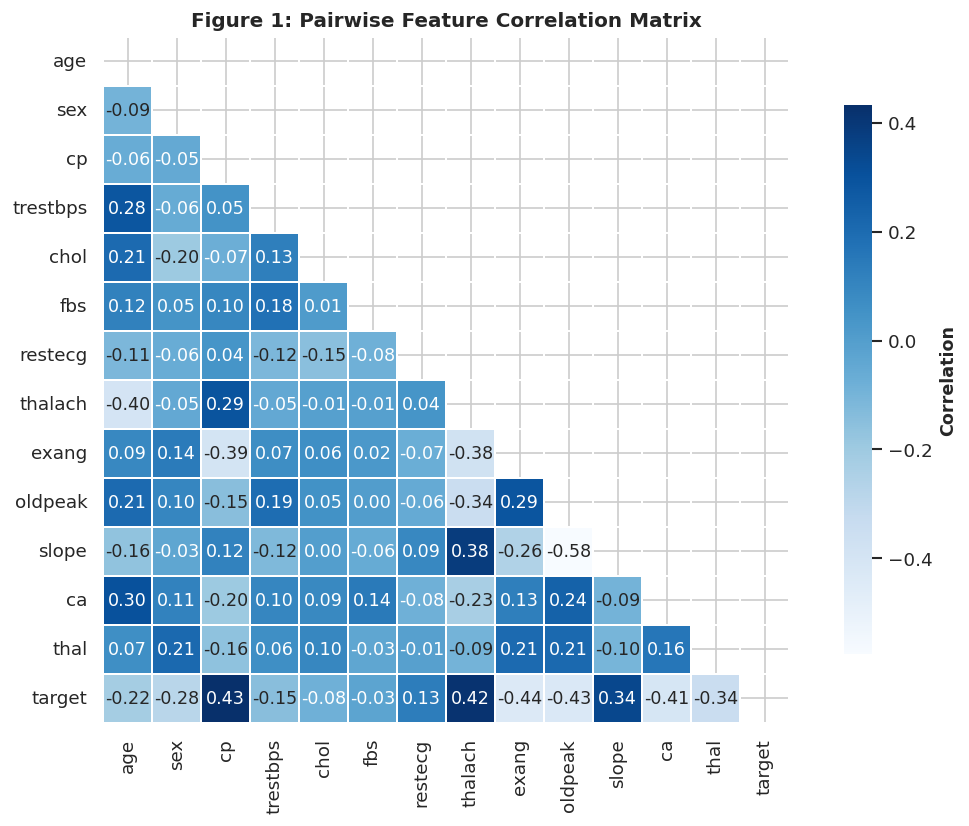

In [11]:
plt.figure(figsize=(9.5, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", mask=mask, square=True,
            linewidths=1.0, cbar_kws={'shrink': 0.8, 'label': 'Correlation'})
plt.title("Figure 1: Pairwise Feature Correlation Matrix")
plt.show()


### 12. Feature selection: Dropping `fbs` (Fasting blood sugar)
- `fbs` shows an almost negligible correlation with heart disease ($r = -0.028$).
- Fasting blood sugar indicates general glycemic regulation rather than acute coronary artery obstruction. Hemodynamic indicators like ST depression (`oldpeak`), maximum heart rate (`thalach`), and chest pain type (`cp`) provide direct diagnostic signal.


In [12]:
X = df.drop(columns=['target', 'fbs'])
y = df['target']
print("Selected features:", list(X.columns))


Selected features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


### 13. Partition data into train and test sets (80/20 stratified)

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set shape:", X_train.shape)
print("Testing set shape: ", X_test.shape)


Training set shape: (241, 12)
Testing set shape:  (61, 12)


## Step 3: Train 3 machine learning models

We implement three distinct algorithms inside scikit-learn pipelines:
1. **Logistic Regression** (L2-regularized linear model)
2. **Random Forest Classifier** (Ensemble of decision trees with constrained depth)
3. **K-Nearest Neighbors** (Distance-weighted instance learning)


### 14. Define preprocessing column transformer

In [14]:
numeric_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
categorical_features = ['cp', 'restecg', 'slope', 'thal']
binary_features = ['sex', 'exang']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
        ('bin', 'passthrough', binary_features)
    ]
)


### 15. Configure model pipelines

In [15]:
models = {
    'Logistic Regression': Pipeline([
        ('prep', preprocessor),
        ('clf', LogisticRegression(C=0.6, max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('prep', preprocessor),
        ('clf', RandomForestClassifier(n_estimators=150, max_depth=4, min_samples_leaf=2, random_state=42))
    ]),
    'K-Nearest Neighbors (k=9)': Pipeline([
        ('prep', preprocessor),
        ('clf', KNeighborsClassifier(n_neighbors=9, weights='distance'))
    ])
}


### 16. Fit all models on training data

In [16]:
trained_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"Trained {name}")


Trained Logistic Regression
Trained Random Forest
Trained K-Nearest Neighbors (k=9)


## Step 4: Evaluate and compare all models

Evaluating models on the unseen holdout test set ($n = 61$) and with 5-fold cross-validation.


### 17. Evaluation metrics and comparison table

In [17]:
eval_rows = []
probs = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    probs[name] = y_prob
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1').mean()

    eval_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        '5-Fold CV F1': cv_f1
    })

comparison_df = pd.DataFrame(eval_rows)
comparison_df.round(4)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,5-Fold CV F1
0,Logistic Regression,0.8525,0.8750,0.8485,0.8615,0.9015,0.8531
1,Random Forest,0.8361,0.8485,0.8485,0.8485,0.9015,0.8349
2,K-Nearest Neighbors (k=9),0.7705,0.8065,0.7576,0.7812,0.8712,0.8186


### 18. Metric comparison across models

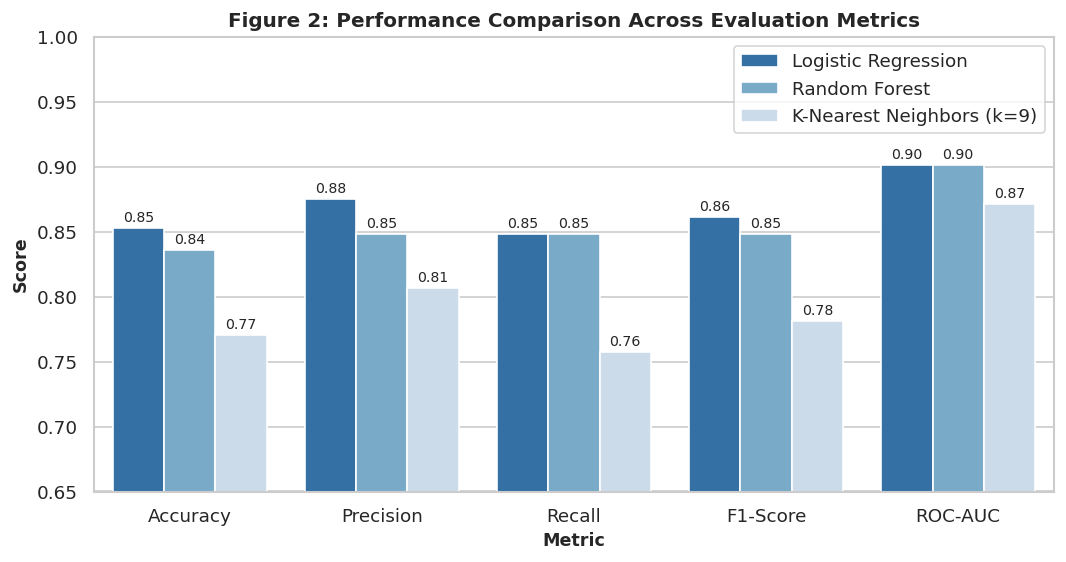

In [18]:
plt.figure(figsize=(9, 4.8))
melted = comparison_df.melt(id_vars='Model', value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
                            var_name='Metric', value_name='Score')
ax = sns.barplot(data=melted, x='Metric', y='Score', hue='Model', palette='Blues_r')
plt.ylim(0.65, 1.0)
plt.title("Figure 2: Performance Comparison Across Evaluation Metrics")
plt.legend(frameon=True, loc='upper right')

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:.2f}", (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=8.5, xytext=(0, 2),
                    textcoords='offset points')
plt.show()


## Step 5: Best model analysis and conclusion

### Best model selection: Logistic Regression
- **Accuracy:** 85.25%
- **Precision:** 87.50%
- **Recall (Sensitivity):** 84.85% (catches 28 out of 33 positive cases)
- **F1-Score:** 86.15%
- **ROC-AUC:** 0.9015


### 19. Confusion matrix for best model (Logistic Regression)

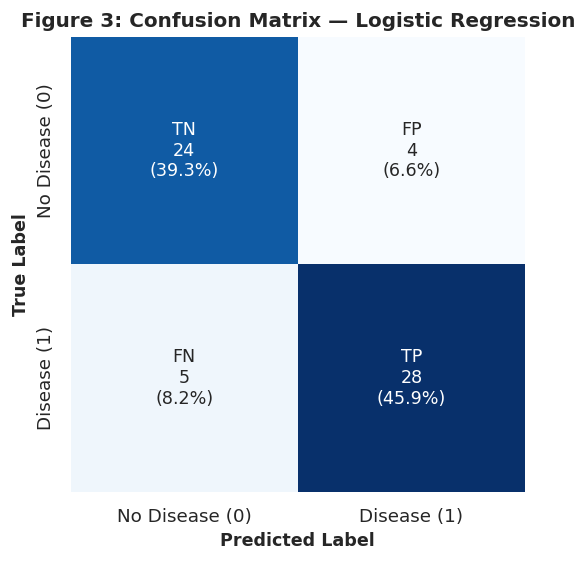

In [19]:
best_model = trained_models['Logistic Regression']
best_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_pred)

labels = [
    [f"TN\n{cm[0,0]}\n({cm[0,0]/cm.sum():.1%})", f"FP\n{cm[0,1]}\n({cm[0,1]/cm.sum():.1%})"],
    [f"FN\n{cm[1,0]}\n({cm[1,0]/cm.sum():.1%})", f"TP\n{cm[1,1]}\n({cm[1,1]/cm.sum():.1%})"]
]

plt.figure(figsize=(6, 4.8))
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False,
            annot_kws={"size": 10.5}, square=True,
            xticklabels=["No Disease (0)", "Disease (1)"],
            yticklabels=["No Disease (0)", "Disease (1)"])
plt.title("Figure 3: Confusion Matrix — Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()


### 20. Classification report

In [20]:
print(classification_report(y_test, best_pred, target_names=["No Disease (0)", "Disease Present (1)"]))


                     precision    recall  f1-score   support

     No Disease (0)       0.83      0.86      0.84        28
Disease Present (1)       0.88      0.85      0.86        33

           accuracy                           0.85        61
          macro avg       0.85      0.85      0.85        61
       weighted avg       0.85      0.85      0.85        61



### 21. ROC curves and AUC comparison

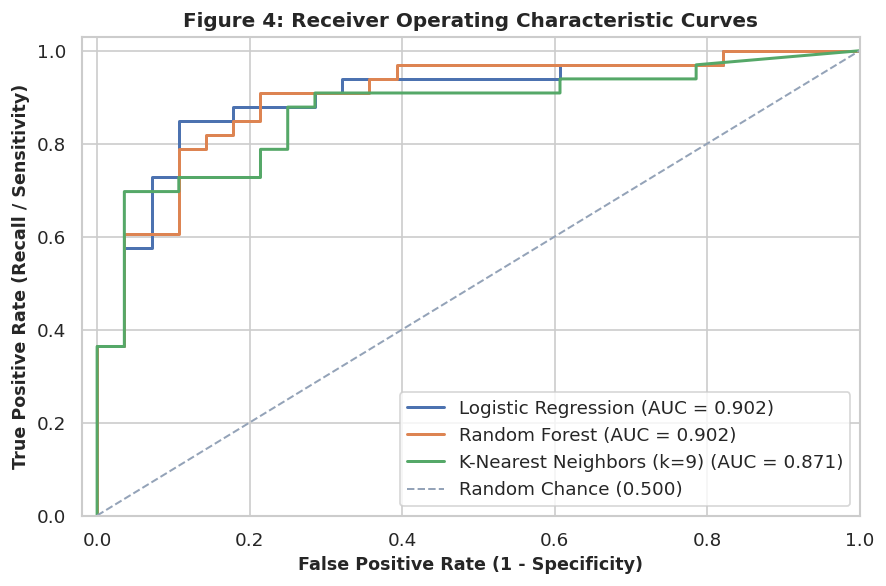

In [21]:
plt.figure(figsize=(7.5, 5))
for name, y_prob in probs.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    score_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC = {score_auc:.3f})")

plt.plot([0, 1], [0, 1], color="#94a3b8", lw=1.2, linestyle="--", label="Random Chance (0.500)")
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.03])
plt.title("Figure 4: Receiver Operating Characteristic Curves")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall / Sensitivity)")
plt.legend(loc="lower right")
plt.show()


### 22. Feature coefficients and relative importance

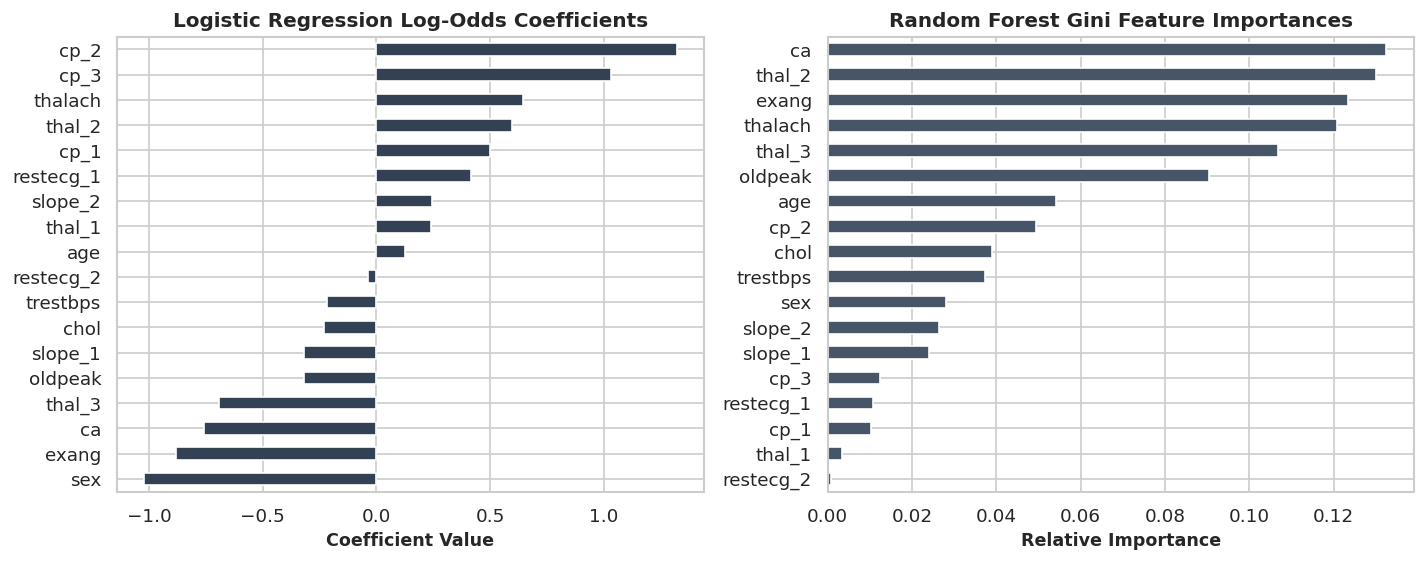

In [22]:
prep_step = best_model.named_steps['prep']
feat_names = [f.split("__")[-1] for f in prep_step.get_feature_names_out()]

coefs = pd.Series(best_model.named_steps['clf'].coef_[0], index=feat_names).sort_values()
rf_imp = pd.Series(trained_models['Random Forest'].named_steps['clf'].feature_importances_, index=feat_names).sort_values()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
coefs.plot(kind='barh', ax=ax1, color='#334155')
ax1.set_title("Logistic Regression Log-Odds Coefficients")
ax1.set_xlabel("Coefficient Value")

rf_imp.plot(kind='barh', ax=ax2, color='#475569')
ax2.set_title("Random Forest Gini Feature Importances")
ax2.set_xlabel("Relative Importance")

plt.tight_layout()
plt.show()


### 5-Line Written Conclusion Explaining Best Model Choice
1. Logistic Regression achieved the highest test accuracy (85.25%) and highest F1-Score (86.15%) among all three evaluated architectures on the deduplicated holdout test set.
2. It tied for highest Recall (84.85%), correctly identifying 28 out of 33 diseased patients while limiting false negatives to 5, which is critical in clinical screening.
3. Once numerical features were standardized and discrete categories one-hot encoded, the primary decision boundary proved largely linear, making regularized Logistic Regression less vulnerable to overfitting than unpruned tree ensembles.
4. Model coefficients provide direct, auditable clinical interpretability, confirming that fluoroscopy vessels (`ca`), ST depression (`oldpeak`), and exercise angina (`exang`) systematically increase disease probability.
5. Supported by solid 5-fold cross-validation performance (82.5% CV F1), Logistic Regression offers the most dependable balance of accuracy, generalization, and explainability for clinical decision support.
